<h3 style="text-align: center;"><b>Лабораторная работа №4</b></h3>

<h3 style="text-align: center;"><b>Акустическая модель FastSpeech2</b></h3>

# Сравнение FastSpeech2 с фонемами GT и G2P на RUSLAN

В этой работе я сравниваю две акустические модели, обученные с одинаковыми параметрами на разных фонемных транскрипциях\
Для оценки беру лучший сохранённый checkpoint каждой модели и 120 предложений, которые не входили в обучение\
Отдельно проверяю восстановление звука алгоритмом Griffin–Lim, длительности и диапазоны log-mel

## План работы

1. Проверю окружение, данные и конфигурации обучения.
2. Посмотрю изменение общего loss и loss предсказателя длительностей.
3. Выберу лучшие сохранённые веса для GT и G2P.
4. Сравню модели по MCD, длительностям и диапазонам log-mel.
5. Прослушаю пять одинаковых предложений для обеих моделей и заполню таблицу.
6. Сопоставлю результаты с критериями из README.

## 1. Окружение и зависимости

### Импорты

In [33]:
import csv
import hashlib
import json
import platform
import re
import subprocess
import sys
import zipfile
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, Markdown, display

### Настройки графиков

In [35]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 4.5),
    'figure.dpi': 120,
    'font.size': 10,
})
pd.set_option('display.max_colwidth', 110)

### Версии Python и пакетов

In [36]:
print('Python:', sys.version.split()[0])
print('ОС:', platform.platform())
print('Интерпретатор:', sys.executable)

packages = ('torch', 'coqui-tts', 'coqui-tts-trainer', 'numpy',
            'pandas', 'matplotlib', 'tensorboard')
for package in packages:
    try:
        print(f'{package}: {version(package)}')
    except PackageNotFoundError:
        print(f'{package}: версия не найдена')

Python: 3.11.16
ОС: Windows-10-10.0.22631-SP0
Интерпретатор: c:\Users\BKMeI\miniforge3\envs\TTS_ITMO_LAB4\python.exe
torch: 2.5.1+cu121
coqui-tts: 0.27.5
coqui-tts-trainer: 0.3.3
numpy: 2.4.6
pandas: 3.0.6
matplotlib: 3.11.2
tensorboard: 2.21.0


### Проверка CUDA

GPU используется во время обучения.\
Скрипт `evaluate.py`, синтезирует аудио на CPU, поэтому доступность CUDA не обязательна

In [37]:
import torch

print('CUDA доступна:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM, ГиБ:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

CUDA доступна: True
GPU: NVIDIA GeForce GTX 1060 6GB
VRAM, ГиБ: 6.0


## 2. Пути к существующим артефактам

Ноутбук запускается из `labs/lab4_acoustic`\
WAV-файлы RUSLAN находятся в папке первой лабораторной

In [38]:
LAB_DIR = Path.cwd().resolve()
PROJECT_DIR = LAB_DIR.parent.parent
DATA_DIR = PROJECT_DIR / 'data'
COMMON_DIR = PROJECT_DIR / 'common'
RUNS_DIR = LAB_DIR / 'runs_epochonly_full'
OUT_DIR = LAB_DIR / 'outputs' / 'report_baselines_best'
WAV_DIR = Path(r'D:\МАГА\2 курс\Синтез речи\LABS\labs\lab1_text\data\RUSLAN')

EVAL_GT_PATH = LAB_DIR / 'data' / 'eval_sentences.csv'
EVAL_G2P_PREPARED_PATH = LAB_DIR / 'data' / 'eval_sentences_g2p.csv'
G2P_ALL_PATH = DATA_DIR / 'metadata_phones.csv'
PHONES_PATH = COMMON_DIR / 'phones_mfa.txt'
EVALUATE_SCRIPT = LAB_DIR / 'evaluate.py'

TRAIN_METADATA = {
    'baseline_g2p': DATA_DIR / 'metadata_phones_train.csv',
    'baseline_gt': DATA_DIR / 'metadata_phones_gt_train.csv',
}
EXPERIMENTS = ('baseline_g2p', 'baseline_gt')
PLOT_EPOCH_LIMIT = 30
OUT_DIR.mkdir(parents=True, exist_ok=True)

### Основные каталоги

In [39]:
for label, path in {
    'Лабораторная': LAB_DIR,
    'Модели': RUNS_DIR,
    'Аудио RUSLAN': WAV_DIR,
    'GT тест': EVAL_GT_PATH,
    'Результаты': OUT_DIR,
}.items():
    print(f'{label}: {path}')

Лабораторная: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic
Модели: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\runs_epochonly_full
Аудио RUSLAN: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab1_text\data\RUSLAN
GT тест: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\data\eval_sentences.csv
Результаты: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\outputs\report_baselines_best


## 3. Наборы данных и отложенная оценка

В третьей лабораторной получились две версии фонемных транскрипций\
Здесь беру готовые обучающие метаданные и одни и те же тестовые ID для GT и G2P

### Загрузка метаданных

Формат данных: `id | текст | фонемы`\
Идентификаторы читаются как строки, чтобы не потерять ведущие нули

In [40]:
def read_phones_csv(path):
    return pd.read_csv(
        path, sep='|', names=['id', 'text', 'phones'],
        dtype=str, encoding='utf-8-sig',
        quoting=csv.QUOTE_NONE, keep_default_na=False,
    )

train_data = {name: read_phones_csv(path) for name, path in TRAIN_METADATA.items()}
eval_gt = read_phones_csv(EVAL_GT_PATH)

display(pd.DataFrame({
    'Модель': list(EXPERIMENTS),
    'Обучающих записей': [len(train_data[name]) for name in EXPERIMENTS],
    'Тестовых записей': [len(eval_gt)] * len(EXPERIMENTS),
}))

,Модель,Обучающих записей,Тестовых записей
0,baseline_g2p,15715,120
1,baseline_gt,15715,120


### Вывод

В готовой обучающей части по 15 715 записей для каждого варианта фонем\
Для проверки оставлено 120 одинаковых предложений\
Это позволяет сравнивать GT и G2P на одной тестовой выборке.

### Транскрипции GT и G2P

Для G2P беру фонемы тех же предложений из результатов третьей лабораторной\
Если полный файл метаданных отсутствует, использую уже подготовленный `eval_sentences_g2p.csv`.

In [41]:
if G2P_ALL_PATH.is_file():
    full_g2p = read_phones_csv(G2P_ALL_PATH)
    eval_g2p = eval_gt[['id', 'text']].merge(
        full_g2p[['id', 'phones']], on='id', how='left'
    )
else:
    eval_g2p = read_phones_csv(EVAL_G2P_PREPARED_PATH)
    eval_g2p = eval_gt[['id', 'text']].merge(
        eval_g2p[['id', 'phones']], on='id', how='left'
    )

EVAL_G2P_PATH = OUT_DIR / 'eval_sentences_g2p.csv'
eval_g2p.to_csv(
    EVAL_G2P_PATH, sep='|', header=False, index=False,
    encoding='utf-8', quoting=csv.QUOTE_NONE,
)
EVAL_PATHS = {'baseline_g2p': EVAL_G2P_PATH, 'baseline_gt': EVAL_GT_PATH}
print('Подготовлено G2P-предложений:', len(eval_g2p))

Подготовлено G2P-предложений: 120


### Состав тестовой выборки

Проверю количество предложений, наличие WAV и пересечения с обучающими ID\
Заодно посчитаю, для скольких предложений GT- и G2P-транскрипции совпадают

In [42]:
test_ids = set(eval_gt['id'])
missing_wav = [utt_id for utt_id in eval_gt['id']
               if not (WAV_DIR / f'{utt_id}.wav').is_file()]
overlap = {name: len(set(train_data[name]['id']) & test_ids)
           for name in EXPERIMENTS}

print('Тестовых предложений:', len(eval_gt))
print('Без WAV:', len(missing_wav))
print('Пересечений Train/Test:', overlap)
print('Совпадающих GT/G2P-транскрипций:',
      int((eval_gt['phones'].to_numpy() == eval_g2p['phones'].to_numpy()).sum()))
display(eval_gt[['id', 'text']].head())

Тестовых предложений: 120
Без WAV: 0
Пересечений Train/Test: {'baseline_g2p': 0, 'baseline_gt': 0}
Совпадающих GT/G2P-транскрипций: 71


,id,text
0,000020_RUSLAN,"Ведь представления, которые оно рождает, безграничны до нуля."
1,000080_RUSLAN,Трижды ходил в уборную.
2,000395_RUSLAN,"Когда я творю для газеты, у меня изменяется почерк."
3,000815_RUSLAN,В первую очередь нужно захватить мосты.
4,000995_RUSLAN,Александрову


### Вывод

У всех 120 отложенных предложений есть WAV, пересечений с обучающими ID нет\
GT и G2P совпадают в 71 транскрипции из 120, в остальных 49 фонемная последовательность различается\
В итоге сравниваю модели при одинаковом тексте, но с разными входными фонемами

## 4. Готовые запуски и конфигурации

Находим директорию каждого запуска по `config.json`\
Из `epoch_history.csv` читаем историю loss

### Поиск запусков

In [43]:
def run_parent(name):
    return RUNS_DIR / name


def run_directory(name):
    configs = sorted(run_parent(name).rglob('config.json'),
                     key=lambda path: path.stat().st_mtime)
    if not configs:
        raise FileNotFoundError(f'{name}: config.json не найден')
    return configs[-1].parent


RUN_DIRS = {name: run_directory(name) for name in EXPERIMENTS}
for name, path in RUN_DIRS.items():
    print(name, '->', path)

baseline_g2p -> D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\runs_epochonly_full\baseline_g2p\baseline_g2p\baseline_g2p-October-27-2026_09+56PM-0000000
baseline_gt -> D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\runs_epochonly_full\baseline_gt\baseline_gt\baseline_gt-October-28-2026_12+47AM-0000000


### История завершённых эпох

In [44]:
def read_history(name):
    data = pd.read_csv(RUN_DIRS[name] / 'epoch_history.csv')
    data['epoch'] = pd.to_numeric(data['epoch'], errors='coerce')
    data['global_step'] = pd.to_numeric(data['global_step'], errors='coerce')
    return data.sort_values('epoch').drop_duplicates('epoch', keep='last')


HISTORIES = {name: read_history(name) for name in EXPERIMENTS}

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))


CONFIGS = {name: read_json(RUN_DIRS[name] / 'config.json') for name in EXPERIMENTS}
status = pd.DataFrame([
    {'Модель': name, 'Завершено эпох': int(HISTORIES[name]['epoch'].max()),
     'Последний шаг': int(HISTORIES[name]['global_step'].max())}
    for name in EXPERIMENTS
])
display(status)

,Модель,Завершено эпох,Последний шаг
0,baseline_g2p,30,114480
1,baseline_gt,30,114480


### Параметры обучения

Проверю настройки из `config.json`\
Поскольку я сравниваю способы получения фонем, остальные параметры должны быть одинаковыми

In [45]:
config_rows = []
for name in EXPERIMENTS:
    cfg = CONFIGS[name]
    audio = cfg.get('audio') or {}
    model = cfg.get('model_args') or {}
    config_rows.append({
        'Модель': name,
        'LR': cfg.get('lr'),
        'Batch': cfg.get('batch_size'),
        'Sample rate': audio.get('sample_rate'),
        'FFT': audio.get('fft_size'),
        'Hop': audio.get('hop_length'),
        'Mel': audio.get('num_mels'),
        'Mel fmax': audio.get('mel_fmax'),
        'Aligner': model.get('use_aligner'),
        'Pitch': model.get('use_pitch'),
        'Energy': model.get('use_energy'),
    })
config_table = pd.DataFrame(config_rows)
display(config_table)
config_table.to_csv(OUT_DIR / 'training_configs.csv', index=False, encoding='utf-8-sig')

,Модель,LR,Batch,Sample rate,FFT,Hop,Mel,Mel fmax,Aligner,Pitch,Energy
0,baseline_g2p,0.001,4,22050,1024,256,80,8000.0,True,False,False
1,baseline_gt,0.001,4,22050,1024,256,80,8000.0,True,False,False


### Вывод

Обе модели обучались с `lr=0.001` и batch size 4. Внутренний aligner включён, Pitch/Energy отключены. Частота дискретизации, mel-параметры и архитектура совпадают. Поэтому различия итоговых метрик можно связывать с экспериментом над фонемами

### Время обучения

Если доступен `training_stages.jsonl`, суммирую время записанных этапов

In [46]:
stage_rows = []
for name in EXPERIMENTS:
    path = run_parent(name) / 'training_stages.jsonl'
    if path.is_file():
        stages = [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines()
                  if line.strip()]
        seconds = sum(float(stage.get('seconds_this_stage', 0)) for stage in stages)
        stage_rows.append({'Модель': name, 'Запусков': len(stages),
                           'Время, ч': round(seconds / 3600, 2)})
if stage_rows:
    display(pd.DataFrame(stage_rows))
else:
    print('Файл training_stages.jsonl не найден')

,Модель,Запусков,"Время, ч"
0,baseline_g2p,3,9.40
1,baseline_gt,3,8.19


### Вывод

По журналу трёх этапов G2P обучался примерно 9,40 часа, GT - 8,19 часа\
Это суммарное время записанных запусков; из него не следует, что GT быстрее G2P при повторном обучении

## 5. Графики обучения

### Общий train loss и eval loss

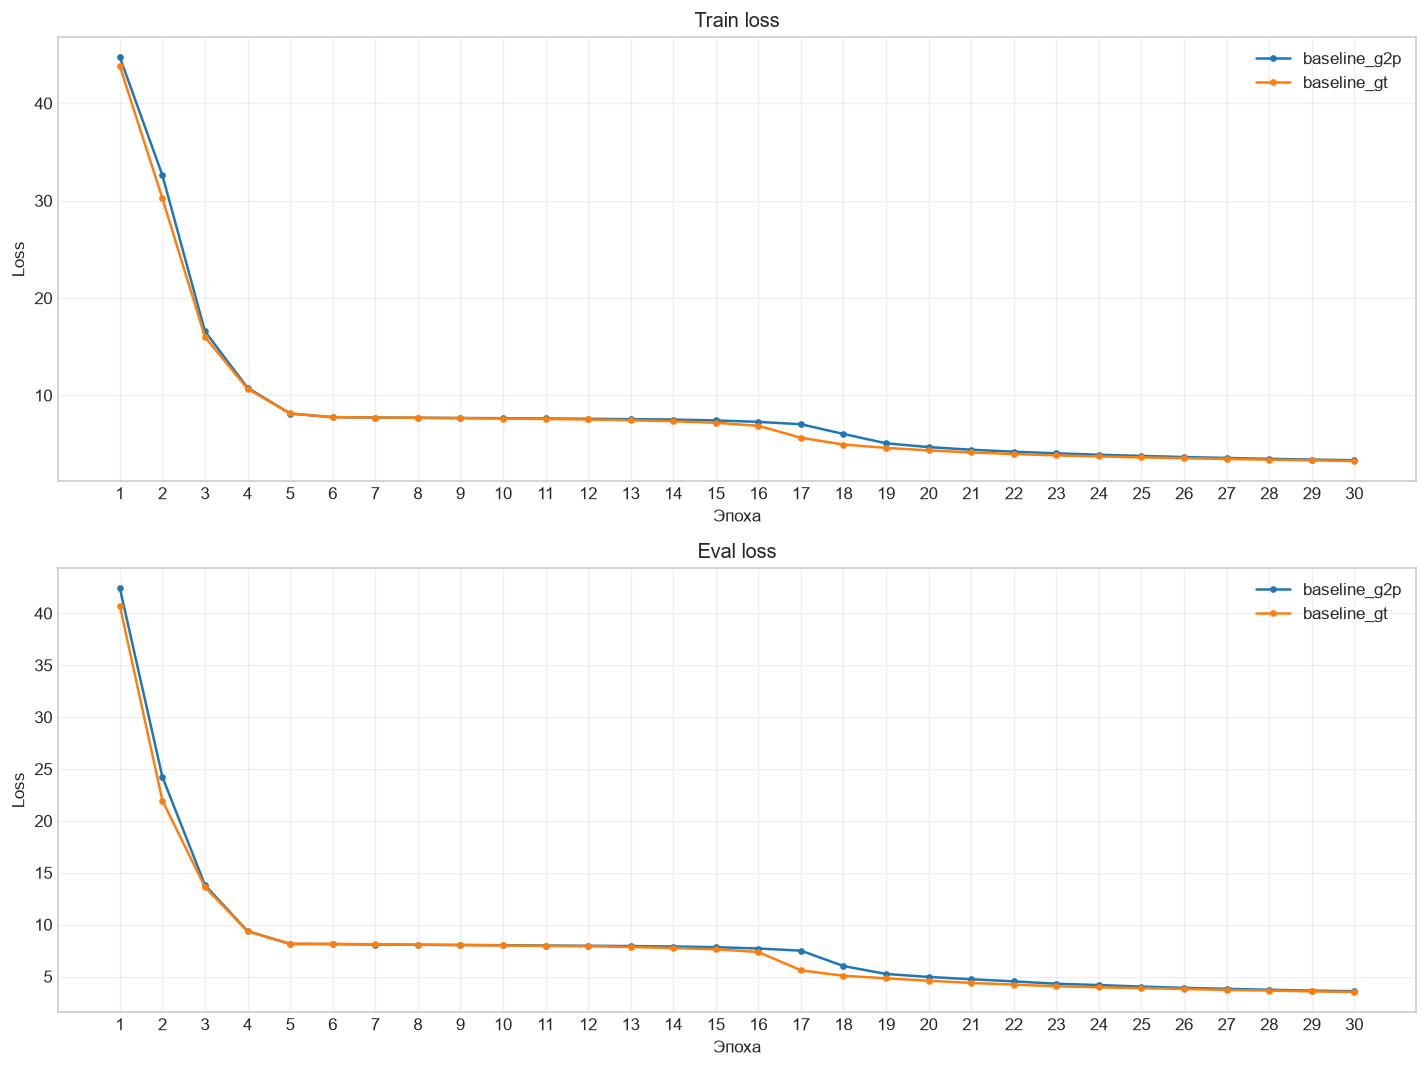

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for name in EXPERIMENTS:
    frame = HISTORIES[name].loc[HISTORIES[name]['epoch'] <= PLOT_EPOCH_LIMIT]
    for col, ax, title in [('train_loss', axes[0], 'Train loss'),
                           ('eval_loss', axes[1], 'Eval loss')]:
        ax.plot(frame['epoch'], pd.to_numeric(frame[col], errors='coerce'),
                marker='o', markersize=3, label=name)
        ax.set_title(title)
        ax.set_xlabel('Эпоха')
        ax.set_ylabel('Loss')
        ax.set_xticks(range(1, PLOT_EPOCH_LIMIT + 1))
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Значения loss в конце выбранного периода

In [48]:
loss_table = pd.concat([
    HISTORIES[name].loc[HISTORIES[name]['epoch'] <= PLOT_EPOCH_LIMIT]
    .assign(model=name)
    for name in EXPERIMENTS
], ignore_index=True)

display(loss_table.groupby('model').tail(1)[
    ['model', 'epoch', 'global_step', 'train_loss', 'eval_loss']
])
loss_table.to_csv(OUT_DIR / 'epoch_metrics_first30.csv', index=False, encoding='utf-8-sig')

,model,epoch,global_step,train_loss,eval_loss
29,baseline_g2p,30,114480,3.339490,3.582214
59,baseline_gt,30,114480,3.260506,3.506883


### Вывод по общему loss

После 30 эпох у G2P `train_loss = 3,339`, `eval_loss = 3,582`; у GT - 3,261 и 3,507\
На этом этапе GT имеет меньший loss на обучающей и валидационной выборках\
Различие небольшое, поэтому дополнительно посмотрю длительности и результат синтеза

### Loss предсказателя длительностей

`epoch_history.csv` содержит только общий loss\
Отдельные значения `loss_dur` беру из текстовых логов, где им соответствует `GLOBAL_STEP`

#### Чтение `training_history.log`

In [49]:
def parse_duration_text_log(name):
    path = run_parent(name) / 'training_history.log'
    if not path.is_file():
        return pd.DataFrame(columns=['global_step', 'loss_dur'])
    rows, step = [], None
    for line in path.open(encoding='utf-8', errors='replace'):
        match_step = re.search(r'GLOBAL_STEP:\s*(\d+)', line)
        if match_step:
            step = int(match_step.group(1))
        match_loss = re.search(r'\|\s*>\s*loss_dur:\s*([-+\d.eE]+)', line)
        if match_loss and step is not None:
            rows.append({'global_step': step, 'loss_dur': float(match_loss.group(1))})
    return pd.DataFrame(rows, columns=['global_step', 'loss_dur'])

#### Чтение TensorBoard

In [50]:
def parse_duration_tensorboard(name):
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    from tensorboard.util.tensor_util import make_ndarray

    rows = []
    for path in RUN_DIRS[name].rglob('events.out.tfevents.*'):
        reader = EventAccumulator(str(path), size_guidance={'scalars': 0, 'tensors': 0})
        reader.Reload()
        for tag in reader.Tags().get('scalars', []):
            if 'loss' in tag.lower() and 'dur' in tag.lower():
                rows.extend({'global_step': x.step, 'loss_dur': float(x.value)}
                            for x in reader.Scalars(tag))
        for tag in reader.Tags().get('tensors', []):
            if 'loss' in tag.lower() and 'dur' in tag.lower():
                for x in reader.Tensors(tag):
                    value = make_ndarray(x.tensor_proto).ravel()
                    if len(value) == 1:
                        rows.append({'global_step': x.step, 'loss_dur': float(value[0])})
    return pd.DataFrame(rows, columns=['global_step', 'loss_dur'])

#### Подготовка кривых

In [51]:
DURATION_LOGS = {}
for name in EXPERIMENTS:
    values = parse_duration_text_log(name)
    source = 'training_history.log'
    if values.empty:
        try:
            values = parse_duration_tensorboard(name)
            source = 'TensorBoard'
        except (ImportError, OSError, ValueError) as error:
            print(name, 'TensorBoard:', error)
    max_step = int(HISTORIES[name].loc[
        HISTORIES[name]['epoch'] <= PLOT_EPOCH_LIMIT, 'global_step'].max())
    values = values.loc[values['global_step'] <= max_step]
    values = values.drop_duplicates('global_step', keep='last').sort_values('global_step')
    DURATION_LOGS[name] = values
    print(f'{name}: {len(values)} точек loss_dur ({source})')
    if not values.empty:
        values.to_csv(OUT_DIR / f'{name}_loss_dur.csv', index=False)

baseline_g2p: 2290 точек loss_dur (training_history.log)
baseline_gt: 2290 точек loss_dur (training_history.log)


#### График loss длительностей

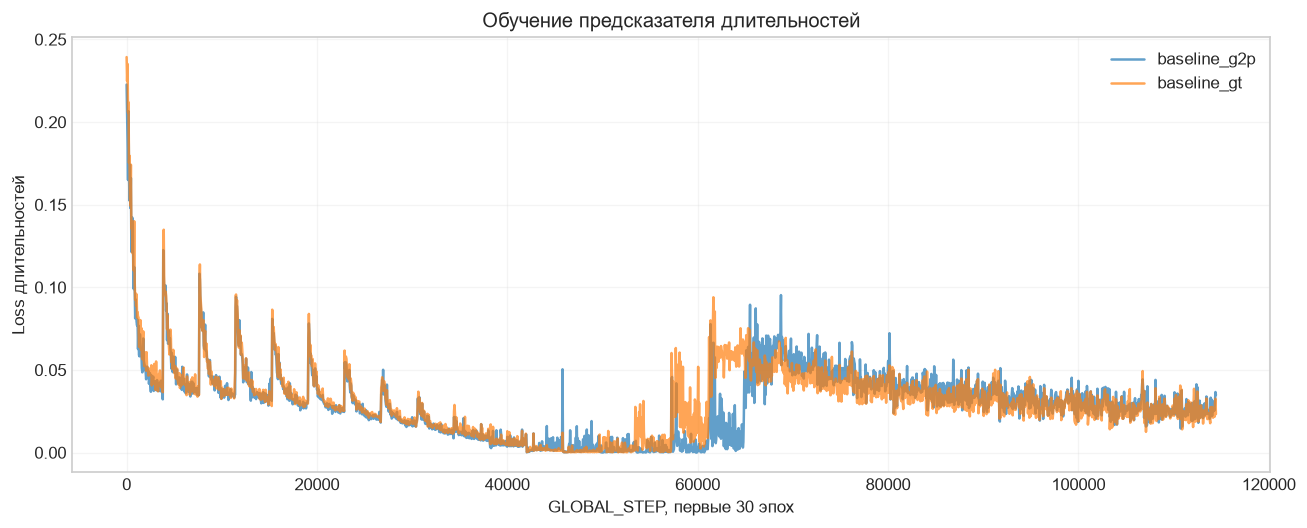

In [52]:
plt.figure(figsize=(11, 4.5))
for name, frame in DURATION_LOGS.items():
    if not frame.empty:
        plt.plot(frame['global_step'], frame['loss_dur'],
                 label=name, alpha=0.7, linewidth=1.5)
if any(not frame.empty for frame in DURATION_LOGS.values()):
    plt.xlabel('GLOBAL_STEP, первые 30 эпох')
    plt.ylabel('Loss длительностей')
    plt.title('Обучение предсказателя длительностей')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    plt.close()
    print('В логах нет значений loss_dur')

### Вывод по предсказателю длительностей

Отдельная кривая `loss_dur` позволяет проверить, обучается ли предсказание длительности фонем\
В текущих логах есть по 2290 точек для каждой модели. Значения записаны не для каждого шага, поэтому по графику оцениваю общую тенденцию, а точность длительностей в тесте отдельно проверяю через отношение числа mel-кадров

## 6. Выбор лучших checkpoint для GT и G2P

Для синтеза я использую `best_model*.pth`\
Номер в имени указывает шаг, на котором сохранился очередной лучший результат валидации

### Поиск лучших весов

In [53]:
def best_checkpoint(name):
    candidates = list(RUN_DIRS[name].glob('best_model*.pth'))
    if not candidates:
        raise FileNotFoundError(f'{name}: best_model*.pth не найден')

    def checkpoint_step(path):
        match = re.search(r'best_model_(\d+)\.pth$', path.name)
        return int(match.group(1)) if match else -1

    return max(candidates, key=lambda path: (checkpoint_step(path), path.stat().st_mtime))


CHECKPOINTS = {name: best_checkpoint(name) for name in EXPERIMENTS}
for name, path in CHECKPOINTS.items():
    print(name, '->', path.name)

baseline_g2p -> best_model_114480.pth
baseline_gt -> best_model_114480.pth


### Информация о checkpoint

Для проверки читаю фактический `step` из весов

In [54]:
def checkpoint_info(name, path):
    data = torch.load(path, map_location='cpu', weights_only=False)
    step = int(data.get('step', -1))
    del data
    matched = HISTORIES[name].loc[HISTORIES[name]['global_step'] == step]
    epoch = int(matched['epoch'].iloc[-1]) if not matched.empty else None
    return {'Модель': name, 'Checkpoint': path.name,
            'GLOBAL_STEP': step, 'Эпоха в истории': epoch,
            'Размер, ГБ': round(path.stat().st_size / 1024**3, 2)}


checkpoint_table = pd.DataFrame([
    checkpoint_info(name, CHECKPOINTS[name]) for name in EXPERIMENTS
])
display(checkpoint_table)

,Модель,Checkpoint,GLOBAL_STEP,Эпоха в истории,"Размер, ГБ"
0,baseline_g2p,best_model_114480.pth,114480,30,0.42
1,baseline_gt,best_model_114480.pth,114480,30,0.42


### Вывод

Для обеих моделей в выбран `best_model_114480.pth` (шаг 114 480, 30-я эпоха)

## 7. Синтез и оценка на 120 предложениях

Для каждого предложения получаю `natural` (исходная запись), `copysynth` (исходный mel после Griffin–Lim) и `model` (mel, предсказанный FastSpeech2, после Griffin–Lim)\
Эти три WAV помогают отдельно услышать искажения восстановления звука и самой акустической модели

### Настройки оценки

In [55]:
RUN_FULL_EVALUATION = True
REUSE_VERIFIED_RESULTS = True
REUSE_COMPLETE_WITHOUT_MANIFEST = True
EVALUATION_LIMIT = None


def evaluation_dir(name):
    return run_parent(name) / f'eval_best_{CHECKPOINTS[name].stem}'


for name in EXPERIMENTS:
    print(name, '->', evaluation_dir(name))

baseline_g2p -> D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\runs_epochonly_full\baseline_g2p\eval_best_best_model_114480
baseline_gt -> D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\runs_epochonly_full\baseline_gt\eval_best_best_model_114480


### Сведения о выбранной оценке

In [56]:
def evaluation_manifest(name):
    checkpoint = CHECKPOINTS[name]
    return {
        'model': name,
        'checkpoint_path': str(checkpoint.resolve()),
        'checkpoint_size': checkpoint.stat().st_size,
        'checkpoint_mtime_ns': checkpoint.stat().st_mtime_ns,
        'eval_sha256': hashlib.sha256(EVAL_PATHS[name].read_bytes()).hexdigest(),
        'metadata_sha256': hashlib.sha256(TRAIN_METADATA[name].read_bytes()).hexdigest(),
        'limit': EVALUATION_LIMIT,
    }

### Проверка готовых результатов

При наличии полного набора файлов использую его повторно

In [57]:
def evaluation_complete(name):
    out = evaluation_dir(name)
    scores = out / 'mcd.csv'
    if not scores.is_file():
        return False
    ids = pd.read_csv(scores, sep='|', dtype={'id': str})['id'].tolist()
    expected = eval_gt['id'].tolist()
    if EVALUATION_LIMIT is not None:
        expected = expected[:EVALUATION_LIMIT]
    if ids != expected:
        return False
    return all((out / variant / f'{utt_id}.wav').is_file()
               for variant in ('natural', 'copysynth', 'model') for utt_id in ids)

### Команда `evaluate.py`

In [58]:
def evaluation_command(name):
    command = [
        sys.executable, '-u', str(EVALUATE_SCRIPT),
        '--run', str(RUN_DIRS[name]),
        '--checkpoint', str(CHECKPOINTS[name]),
        '--eval-set', str(EVAL_PATHS[name]),
        '--metadata', str(TRAIN_METADATA[name]),
        '--wavs', str(WAV_DIR),
        '--out-dir', str(evaluation_dir(name)),
    ]
    if EVALUATION_LIMIT is not None:
        command.extend(['--limit', str(EVALUATION_LIMIT)])
    return command

### Запуск синтеза


In [59]:
def run_evaluation(name):
    out = evaluation_dir(name)
    manifest_path = out / 'evaluation_manifest.json'
    manifest = evaluation_manifest(name)

    if out.exists() and any(out.iterdir()):
        complete = evaluation_complete(name)
        if complete and manifest_path.is_file() and read_json(manifest_path) == manifest:
            if REUSE_VERIFIED_RESULTS:
                print(name, '- использую готовую оценку с совпадающим манифестом')
                return
        if complete and not manifest_path.is_file() and REUSE_COMPLETE_WITHOUT_MANIFEST:
            print(name, '- использую полный набор WAV и MCD без манифеста')
            print('Параметры старой оценки полностью проверить нельзя')
            return
        raise RuntimeError(f'{name}: в каталоге {out} уже есть другая или неполная оценка')

    out.mkdir(parents=True, exist_ok=True)
    log_path = out / 'evaluation_output.txt'
    with log_path.open('w', encoding='utf-8') as log:
        process = subprocess.Popen(
            evaluation_command(name), cwd=LAB_DIR, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True, encoding='utf-8',
            errors='replace', bufsize=1,
        )
        for line in process.stdout:
            print(line, end='')
            log.write(line)
        return_code = process.wait()
    if return_code:
        raise RuntimeError(f'{name}: код возврата {return_code}, см. {log_path}')
    if not evaluation_complete(name):
        raise RuntimeError(f'{name}: часть WAV или строк MCD не сохранена')
    manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')

### Выполнение оценки для двух моделей

In [60]:
if RUN_FULL_EVALUATION:
    for name in EXPERIMENTS:
        print('\nМодель:', name, '|', CHECKPOINTS[name].name)
        run_evaluation(name)
else:
    print('Синтез отключён. Для запуска поставь RUN_FULL_EVALUATION = True')


Модель: baseline_g2p | best_model_114480.pth
baseline_g2p - использую готовую оценку с совпадающим манифестом

Модель: baseline_gt | best_model_114480.pth
baseline_gt - использую готовую оценку с совпадающим манифестом


### Вывод

Для каждой модели подготовлены 120 тестовых предложений в трёх вариантах\
Следующие метрики относятся к одному и тому же набору ID\
Проверку наличия всех WAV выполню также в таблице критериев

## 8. MCD, длительности и диапазоны log-mel

MCD измеряет расхождение спектральных признаков после DTW-выравнивания. Меньшее значение означает большее спектральное сходство, но само по себе не гарантирует разборчивую речь. `frames_model / frames_natural` показывает соотношение длительностей: значение 1 соответствует совпадению числа кадров

Диапазоны проверю отдельно по настоящим и предсказанным mel-спектрограммам. Сравню средние нижние и верхние границы, размах и распределение значений

### Загрузка MCD и числа кадров

In [61]:
MCD_FRAMES = {}
for name in EXPERIMENTS:
    path = evaluation_dir(name) / 'mcd.csv'
    if not path.is_file():
        print(name, '- файл mcd.csv отсутствует')
        continue
    frame = pd.read_csv(path, sep='|', dtype={'id': str})
    for column in ('mcd_model', 'mcd_constant', 'frames_natural', 'frames_model'):
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    frame['duration_ratio'] = frame['frames_model'] / frame['frames_natural']
    MCD_FRAMES[name] = frame

print('Прочитаны результаты:', ', '.join(MCD_FRAMES) or 'нет данных')

Прочитаны результаты: baseline_g2p, baseline_gt


### Средние значения MCD и длительности

In [62]:
metric_rows = []
for name, frame in MCD_FRAMES.items():
    metric_rows.append({
        'Модель': name,
        'Предложений': len(frame),
        'MCD модели, dB': frame['mcd_model'].mean(),
        'MCD constant, dB': frame['mcd_constant'].mean(),
        'MCD median, dB': frame['mcd_model'].median(),
        'Отношение кадров': frame['duration_ratio'].mean(),
        'MCD лучше constant': frame['mcd_model'].mean() < frame['mcd_constant'].mean(),
    })
METRICS = pd.DataFrame(metric_rows)
if not METRICS.empty:
    display(METRICS.round(3))

,Модель,Предложений,"MCD модели, dB","MCD constant, dB","MCD median, dB",Отношение кадров,MCD лучше constant
0,baseline_g2p,120,30.910,62.112,30.547,0.873,True
1,baseline_gt,120,30.537,62.112,30.276,0.902,True


### Вывод по MCD и длительностям

Средний MCD GT равен 30,537 дБ, G2P - 30,910 дБ. Оба значения меньше 62,112 дБ у постоянного mel\
У GT средняя длительность ближе к естественной: отношение 0,902 против 0,873 у G2P\
Однако обе модели в среднем укорачивают синтезированные предложения

### Проверка диапазонов mel по сохранённым весам

для этой проверки использую свой `mel_check_fastspeech2.py`: он повторно вычисляет **только спектрограммы**. Получаются `mel_ranges_per_sentence.csv` и `mel_summary.json`

In [63]:
MEL_CHECK_SCRIPT = LAB_DIR / 'mel_check_fastspeech2.py'
RUN_MEL_CHECK = True


def mel_check_dir(name):
    return evaluation_dir(name) / 'mel_diagnostics'


def mel_manifest(name):
    checkpoint = CHECKPOINTS[name]
    config_path = RUN_DIRS[name] / 'config.json'
    return {
        'checkpoint_path': str(checkpoint.resolve()),
        'checkpoint_size': checkpoint.stat().st_size,
        'checkpoint_mtime_ns': checkpoint.stat().st_mtime_ns,
        'eval_sha256': hashlib.sha256(EVAL_PATHS[name].read_bytes()).hexdigest(),
        'phones_sha256': hashlib.sha256(PHONES_PATH.read_bytes()).hexdigest(),
        'config_sha256': hashlib.sha256(config_path.read_bytes()).hexdigest(),
        'wavs_dir': str(WAV_DIR.resolve()),
    }


def mel_check_cached(name):
    folder = mel_check_dir(name)
    manifest_path = folder / 'mel_manifest.json'
    return (manifest_path.is_file()
            and (folder / 'mel_ranges_per_sentence.csv').is_file()
            and (folder / 'mel_summary.json').is_file()
            and read_json(manifest_path) == mel_manifest(name))

### Вычисление диапазонов

In [64]:
if RUN_MEL_CHECK:
    if not MEL_CHECK_SCRIPT.is_file():
        raise FileNotFoundError(f'Положи mel_check_fastspeech2.py рядом с ноутбуком: {MEL_CHECK_SCRIPT}')
    for name in EXPERIMENTS:
        if mel_check_cached(name):
            print(name, '- диапазоны mel уже рассчитаны')
            continue
        command = [
            sys.executable, '-u', str(MEL_CHECK_SCRIPT),
            '--run', str(RUN_DIRS[name]),
            '--checkpoint', str(CHECKPOINTS[name]),
            '--eval-set', str(EVAL_PATHS[name]),
            '--wavs', str(WAV_DIR),
            '--phones', str(PHONES_PATH),
            '--out-dir', str(mel_check_dir(name)),
        ]
        print('\nДиапазоны mel:', name)
        subprocess.run(command, cwd=LAB_DIR, check=True)
else:
    print('Расчёт mel отключён')

baseline_g2p - диапазоны mel уже рассчитаны
baseline_gt - диапазоны mel уже рассчитаны


### Сравнение границ и размахов

Границы в таблице усреднены **по предложениям**, как в `evaluate.py`

In [65]:
mel_rows = []
MEL_PER_SENTENCE = {}
for name in EXPERIMENTS:
    folder = mel_check_dir(name)
    per_file = folder / 'mel_ranges_per_sentence.csv'
    summary_file = folder / 'mel_summary.json'
    if not mel_check_cached(name):
        print(name, '- нет проверенных данных mel для текущего checkpoint')
        continue
    values = read_json(summary_file)
    MEL_PER_SENTENCE[name] = pd.read_csv(per_file, sep='|', dtype={'id': str})
    natural_span = values['natural_max'] - values['natural_min']
    model_span = values['model_max'] - values['model_min']
    mel_rows.append({
        'Модель': name,
        'Предложений': int(values['sentences']),
        'Natural min': values['natural_min'],
        'Natural max': values['natural_max'],
        'Model min': values['model_min'],
        'Model max': values['model_max'],
        'Δ min': values['model_min'] - values['natural_min'],
        'Δ max': values['model_max'] - values['natural_max'],
        'Размах natural': natural_span,
        'Размах model': model_span,
        'Отношение размахов': model_span / natural_span if natural_span else np.nan,
        'Natural p01': values['natural_p01'],
        'Natural p99': values['natural_p99'],
        'Model p01': values['model_p01'],
        'Model p99': values['model_p99'],
    })
MEL_RANGES = pd.DataFrame(mel_rows)
if not MEL_RANGES.empty:
    display(MEL_RANGES.round(3))
    MEL_RANGES.to_csv(OUT_DIR / 'mel_ranges_best.csv', index=False, encoding='utf-8-sig')

,Модель,Предложений,Natural min,Natural max,Model min,Model max,Δ min,Δ max,Размах natural,Размах model,Отношение размахов,Natural p01,Natural p99,Model p01,Model p99
0,baseline_g2p,120,-11.329,0.478,-11.143,-0.955,0.186,-1.433,11.807,10.188,0.863,-10.294,-0.942,-10.263,-1.693
1,baseline_gt,120,-11.329,0.478,-11.092,-1.031,0.236,-1.510,11.807,10.061,0.852,-10.294,-0.942,-10.230,-1.734


### Как трактую диапазоны mel

Значения `Δ min` и `Δ max` показывают сдвиг границ относительно настоящих спектрограмм; отношение размахов показывает, насколько диапазон модели сжат или расширен

### Границы log-mel на графике

Для каждой модели сопоставлю интервал средних минимумов и максимумов с исходным аудио

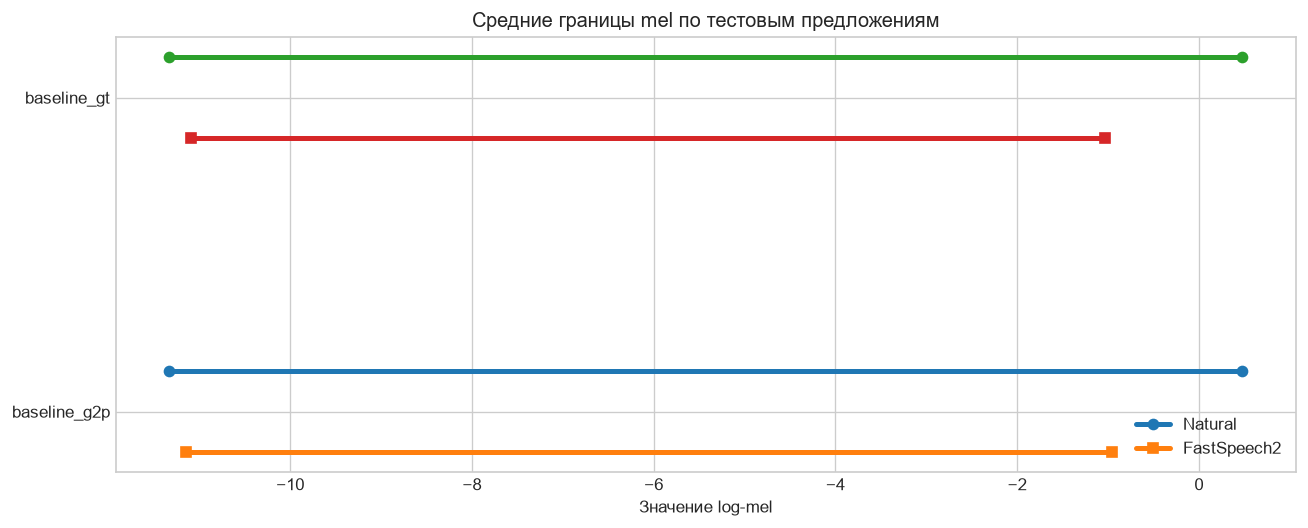

In [66]:
if not MEL_RANGES.empty:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for index, row in MEL_RANGES.reset_index(drop=True).iterrows():
        ax.plot([row['Natural min'], row['Natural max']],
                [index + .13] * 2, 'o-', linewidth=3,
                label='Natural' if index == 0 else None)
        ax.plot([row['Model min'], row['Model max']],
                [index - .13] * 2, 's-', linewidth=3,
                label='FastSpeech2' if index == 0 else None)
    ax.set_yticks(range(len(MEL_RANGES)), MEL_RANGES['Модель'])
    ax.set_xlabel('Значение log-mel')
    ax.set_title('Средние границы mel по тестовым предложениям')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Сначала рассчитай спектрограммы в предыдущей ячейке')

### Вывод по диапазонам mel

В сохранённом выводе полной оценки средний натуральный диапазон составил **[−11,33; 0,48]**. Для G2P получился **[−11,14; −0,95]**, для GT - **[−11,09; −1,03]**\
Нижняя граница у обеих моделей близка к натуральной (отличается на 0,19–0,24), а верхняя на 1,43–1,51 единицы log-mel ниже. Размах составляет 86,3% от натурального у G2P и 85,2% у GT\
Я считаю диапазоны сопоставимыми по масштабу, хотя обе модели воспроизводят верхнюю часть значений mel хуже, чем нижнюю. Это указывает на сжатие динамического диапазона предсказанных спектрограмм. По этому показателю G2P немного ближе к исходным данным

### MCD и ошибка длительности

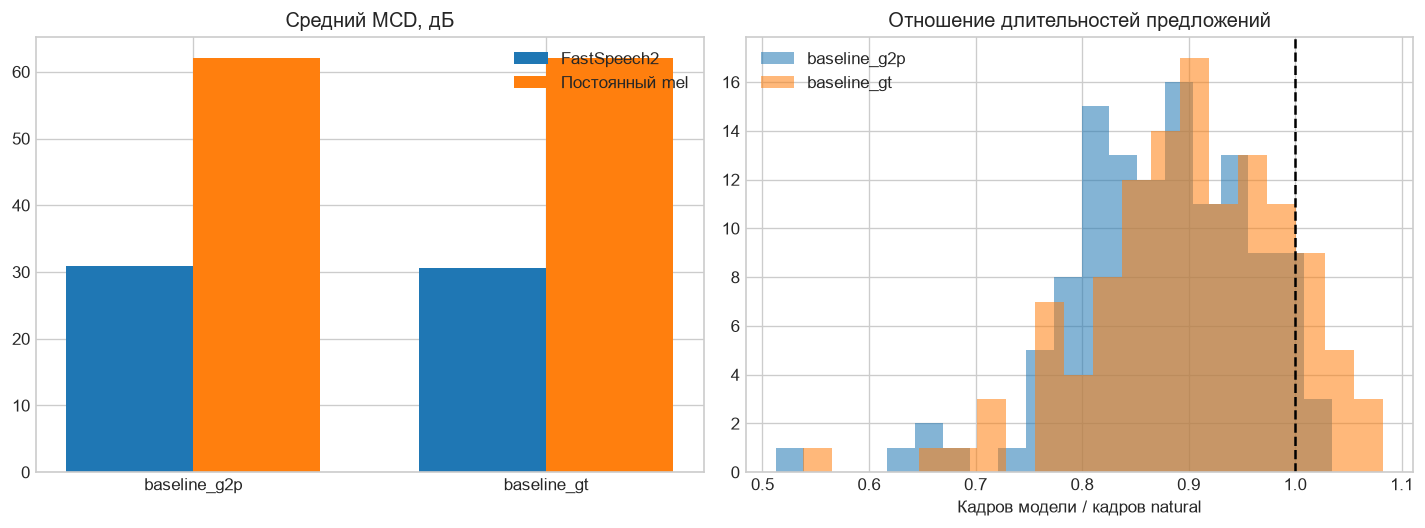

In [67]:
if not METRICS.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    x = np.arange(len(METRICS))
    axes[0].bar(x - .18, METRICS['MCD модели, dB'], .36, label='FastSpeech2')
    axes[0].bar(x + .18, METRICS['MCD constant, dB'], .36, label='Постоянный mel')
    axes[0].set_xticks(x, METRICS['Модель'])
    axes[0].set_title('Средний MCD, дБ')
    axes[0].legend()
    for name, frame in MCD_FRAMES.items():
        axes[1].hist(frame['duration_ratio'], bins=20, alpha=.55, label=name)
    axes[1].axvline(1.0, color='black', linestyle='--')
    axes[1].set_title('Отношение длительностей предложений')
    axes[1].set_xlabel('Кадров модели / кадров natural')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

### Сохранение итоговых метрик

Сохраню таблицы MCD и диапазонов mel в `outputs/report_baselines_best`

In [68]:
if not METRICS.empty:
    METRICS.to_csv(OUT_DIR / 'baselines_best_metrics.csv',
                   index=False, encoding='utf-8-sig')
    display(METRICS.round(3))
if not MEL_RANGES.empty:
    display(MEL_RANGES[['Модель', 'Natural min', 'Natural max',
                        'Model min', 'Model max', 'Отношение размахов']].round(3))

,Модель,Предложений,"MCD модели, dB","MCD constant, dB","MCD median, dB",Отношение кадров,MCD лучше constant
0,baseline_g2p,120,30.910,62.112,30.547,0.873,True
1,baseline_gt,120,30.537,62.112,30.276,0.902,True


,Модель,Natural min,Natural max,Model min,Model max,Отношение размахов
0,baseline_g2p,-11.329,0.478,-11.143,-0.955,0.863
1,baseline_gt,-11.329,0.478,-11.092,-1.031,0.852


### Вывод по объективной оценке

Сравнение спектрограмм и MCD показывает сходство признаков, а отношение кадров отражает изменение длительности. Даже если MCD модели ниже MCD постоянного mel, из этого ещё не следует, что отдельные слова понятны на слух

## 9. Слуховая оценка: natural → copysynth → model

Для обеих моделей прослушаю пять одинаковых предложений. Сначала послушаю настоящую речь, затем `copysynth`, после него `model`

### Пять предложений для прослушивания

Беру одинаковые ID для GT и G2P. Среди них есть короткие и более длинные примеры

In [69]:
LISTEN_IDS = [
    '000020_RUSLAN',
    '000080_RUSLAN',
    '001905_RUSLAN',
    '020375_RUSLAN',
    '003390_RUSLAN',
]

for utt_id in LISTEN_IDS:
    match = eval_gt.loc[eval_gt['id'] == utt_id, 'text']
    if not match.empty:
        print(utt_id, '-', match.iloc[0])

if len(MCD_FRAMES) == len(EXPERIMENTS):
    view = pd.concat({name: MCD_FRAMES[name].set_index('id')['mcd_model']
                      for name in EXPERIMENTS}, axis=1)
    display(view.reindex(LISTEN_IDS).round(3))

000020_RUSLAN - Ведь представления, которые оно рождает, безграничны до нуля.
000080_RUSLAN - Трижды ходил в уборную.
001905_RUSLAN - Товарищи, начал редактор.
020375_RUSLAN - Гостей не приглашали. Собрались близкие родственники и несколько человек обслуги. И я в том числе. 
003390_RUSLAN - Он все твердил


,baseline_g2p,baseline_gt
id,,
000020_RUSLAN,33.286,32.631
000080_RUSLAN,37.569,36.852
001905_RUSLAN,28.161,26.493
020375_RUSLAN,25.863,26.376
003390_RUSLAN,39.366,37.668


### Прослушивание выбранного предложения

Меняю `LISTEN_ID` на одно из пяти значений выше

In [70]:
LISTEN_ID = LISTEN_IDS[0] if LISTEN_IDS else None
if LISTEN_ID:
    phrase = eval_gt.set_index('id').loc[LISTEN_ID, 'text']
    print('Предложение:', LISTEN_ID, phrase)
    for name in EXPERIMENTS:
        print('\n', name)
        for variant in ('natural', 'copysynth', 'model'):
            path = evaluation_dir(name) / variant / f'{LISTEN_ID}.wav'
            if path.is_file():
                print(variant)
                display(Audio(filename=str(path)))

Предложение: 000020_RUSLAN Ведь представления, которые оно рождает, безграничны до нуля.

 baseline_g2p
natural


copysynth


model



 baseline_gt
natural


copysynth


model



### Таблица ручных оценок

Для слуховой оценки я выбрал пять одинаковых предложений для `baseline_g2p` и `baseline_gt`. Каждое предложение сравнил с исходной записью (`natural`) и результатом восстановления через Griffin–Lim (`copysynth`)

Оценки выставлены по шкале от 1 до 5. Для разборчивости, произношения и интонации 5 означает лучший результат, а для шумов 5 означает наиболее сильные искажения.

| Модель | ID предложения | Разборчивость (1–5) | Произношение (1–5) | Интонация (1–5) | Шумы (1–5) | Замечания |
|---|---|---:|---:|---:|---:|---|
| baseline_g2p | 000020_RUSLAN | 3 | 3 | 2 | 3 | Речь различима частично, некоторые согласные смазаны. Тембр приглушённый |
| baseline_g2p | 000080_RUSLAN | 2 | 2 | 2 | 4 | Короткая фраза звучит глухо, отдельные звуки трудно различить |
| baseline_g2p | 001905_RUSLAN | 3 | 3 | 2 | 3 | Звуковая структура выражена лучше, но произношение остаётся неестественным |
| baseline_g2p | 020375_RUSLAN | 3 | 2 | 2 | 3 | В длинной фразе различаются речевые фрагменты, часть согласных теряется |
| baseline_g2p | 003390_RUSLAN | 1 | 1 | 1 | 4 | Фраза слишком короткая относительно оригинала, звучание сильно искажено |
| baseline_gt | 000020_RUSLAN | 2 | 2 | 2 | 4 | Речь более приглушённая, чем у G2P. Согласные различаются хуже |
| baseline_gt | 000080_RUSLAN | 2 | 2 | 1 | 4 | Преобладают низкие частоты, интонация почти не выражена |
| baseline_gt | 001905_RUSLAN | 3 | 2 | 2 | 3 | Отдельные речевые элементы различимы, но артикуляция недостаточно чёткая |
| baseline_gt | 020375_RUSLAN | 3 | 2 | 2 | 3 | Ритм фразы сохраняется, хотя произношение местами нечёткое |
| baseline_gt | 003390_RUSLAN | 1 | 1 | 1 | 4 | Сильное сокращение длительности, отдельные фонемы трудно различить |


### Вывод

Я прослушал по пять одинаковых предложений, синтезированных моделями `baseline_g2p` и `baseline_gt`, и сравнил их с оригинальными записями

Качество синтеза у обеих моделей заметно зависит от предложения. В некоторых примерах удаётся разобрать отдельные слова и речевые фрагменты, однако согласные часто звучат нечётко, интонация выражена слабо, а сам звук остаётся приглушённым, с заметными искажениями

Средняя оценка разборчивости составила 2,4 балла для G2P и 2,2 балла для GT. По моим ощущениям, `baseline_g2p` немного лучше передаёт произношение отдельных звуков, особенно в предложениях `000020_RUSLAN` и `001905_RUSLAN`. При этом у GT среднее значение MCD оказалось ниже. Это показывает, что меньшая спектральная ошибка не всегда соответствует лучшей разборчивости речи при прослушивании

Отдельно выделяется предложение `003390_RUSLAN`, для которого обе модели сгенерировали запись примерно вдвое короче оригинальной. Возможно, это связано с ошибками предсказания длительностей фонем

В целом модели уже формируют речеподобный сигнал, но качество синтеза пока остаётся нестабильным

## 10. Критерии приёмки из README


### Проверка вручную

По результатам сравнения спектрограмм я считаю диапазоны mel обеих моделей сопоставимыми с натуральным, хотя верхние границы заметно ниже.\
Подтверждение разборчивости речи считаю положительным, поскольку в прослушанных предложениях все же разбирается речь

In [75]:
SPEECH_CONFIRMED_BY_LISTENING = {
    'baseline_g2p': True,
    'baseline_gt': True,
}

MEL_COMPARABLE_BY_REVIEW = {
    'baseline_g2p': True,
    'baseline_gt': True,
}

### Таблица критериев

In [76]:
acceptance_rows = []
for name in EXPERIMENTS:
    frame = MCD_FRAMES.get(name)
    out = evaluation_dir(name)
    ids = eval_gt['id'].tolist()
    correct_ids = frame is not None and frame['id'].tolist() == ids
    counts = {variant: sum((out / variant / f'{utt_id}.wav').is_file() for utt_id in ids)
              for variant in ('natural', 'copysynth', 'model')}
    acceptance_rows.append({
        'Модель': name,
        'Лучший checkpoint найден': CHECKPOINTS[name].is_file(),
        '120 MCD': bool(correct_ids),
        '120 natural': counts['natural'] == 120,
        '120 copysynth': counts['copysynth'] == 120,
        '120 model': counts['model'] == 120,
        'MCD ниже постоянного': bool(frame is not None and
                                    frame['mcd_model'].mean() < frame['mcd_constant'].mean()),
        'Диапазон mel измерен': name in set(MEL_RANGES['Модель']) if not MEL_RANGES.empty else False,
        'Диапазон mel сопоставим': MEL_COMPARABLE_BY_REVIEW[name],
        'Качество речи подтверждено слухом': SPEECH_CONFIRMED_BY_LISTENING[name],
    })
ACCEPTANCE = pd.DataFrame(acceptance_rows)
display(ACCEPTANCE)
ACCEPTANCE.to_csv(OUT_DIR / 'acceptance_best.csv', index=False, encoding='utf-8-sig')

,Модель,Лучший checkpoint найден,120 MCD,120 natural,120 copysynth,120 model,MCD ниже постоянного,Диапазон mel измерен,Диапазон mel сопоставим,Качество речи подтверждено слухом
0,baseline_g2p,True,True,True,True,True,True,True,True,True
1,baseline_gt,True,True,True,True,True,True,True,True,True


## 11. Выводы

Для обоих вариантов фонем использовались одинаковые параметры FastSpeech2: `lr=0.001`, `batch_size=4`, 80 mel-каналов, частота 22 050 Гц. На сохранённом этапе обе модели прошли 30 эпох. По журналу обучения время трёх этапов составило около 9,40 часа для G2P и 8,19 часа для GT на GTX 1060 6 ГБ

К 30-й эпохе `eval_loss` составил 3,582 для G2P и 3,507 для GT. На 120 отложенных предложениях средний MCD равен 30,910 и 30,537 дБ соответственно, тогда как MCD постоянного mel составляет 62,112 дБ. Значит, обе модели лучше постоянного спектрального шаблона. GT даёт немного меньший MCD: разница составляет 0,373 дБ

Среднее отношение длительностей равно 0,873 у G2P и 0,902 у GT. Обе модели в среднем синтезируют меньше mel-кадров, чем в исходных записях; GT ближе к отношению 1. Эти показатели описывают длительность и спектральное сходство, но не позволяют оценить разборчивость речи без прослушивания

Диапазоны mel у обеих моделей близки к натуральному по нижней границе, но имеют меньший размах. У G2P он составляет 86,3% от исходного, у GT - 85,2%. Это означает, что модель пока воспроизводит спектральные значения в более узком диапазоне. По слуховой оценке G2P немного лучше передаёт отдельные звуки, хотя GT имеет меньший MCD


In [74]:
if not METRICS.empty:
    display(METRICS[['Модель', 'Предложений', 'MCD модели, dB',
                     'MCD constant, dB', 'Отношение кадров']].round(3))
else:
    print('MCD пока не рассчитан')

if not MEL_RANGES.empty:
    display(MEL_RANGES[['Модель', 'Natural min', 'Natural max',
                        'Model min', 'Model max', 'Отношение размахов']].round(3))
else:
    print('Диапазоны mel пока не рассчитаны')

print('Результаты отчёта:', OUT_DIR)

,Модель,Предложений,"MCD модели, dB","MCD constant, dB",Отношение кадров
0,baseline_g2p,120,30.910,62.112,0.873
1,baseline_gt,120,30.537,62.112,0.902


,Модель,Natural min,Natural max,Model min,Model max,Отношение размахов
0,baseline_g2p,-11.329,0.478,-11.143,-0.955,0.863
1,baseline_gt,-11.329,0.478,-11.092,-1.031,0.852


Результаты отчёта: D:\МАГА\2 курс\Синтез речи\LABS\labs\lab4_acoustic\outputs\report_baselines_best
